# Keşifçi Veri Analizi (EDA) — IEEE-CIS Fraud Detection
## Yapay Zeka Ajanı Tabanlı Finansal Dolandırıcılık Tespit Sistemi

**Amaç:** Ham veri üzerinde dolandırıcılık örüntülerini anlamak, özellik mühendisliği
kararlarını desteklemek ve tez için görsel analiz sunmak.

| Bölüm | İçerik |
|---|---|
| 1 | Veri Yükleme ve Genel Bakış |
| 2 | Fraud Oranı Dağılımı |
| 3 | TransactionAmt Analizi (fraud vs normal) |
| 4 | Zaman Desenleri (saat, gün) |
| 5 | Eksik Değer Analizi |
| 6 | Sayısal Özellik Korelasyonları (fraud ile) |
| 7 | Kategorik Değişken Dağılımları |
| 8 | Kimlik Tablosu Analizi |
| 9 | Özet |

**Not:** EDA ham veri üzerinde yapılır — pipeline öncesi, leakage endişesi yoktur.

## 1. Kütüphaneler ve Veri Yükleme

In [ ]:
import os, gc, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')
PALETTE = {'Normal': '#2196F3', 'Fraud': '#F44336'}

from google.colab import drive
drive.mount('/content/drive')

DRIVE_DATA_PATH = '/content/drive/My Drive/Bitirme/VeriSeti'
SAVE_BASE = '/content/drive/My Drive/Bitirme/15-Mayıs-Cuma/EDA/'
os.makedirs(SAVE_BASE, exist_ok=True)
print(f'EDA cikti klasoru: {SAVE_BASE}')

TRAIN_PATH = f'{DRIVE_DATA_PATH}/train_transaction.csv'
IDENT_PATH = f'{DRIVE_DATA_PATH}/train_identity.csv'

df_tx = pd.read_csv(TRAIN_PATH)
df_id = pd.read_csv(IDENT_PATH)
print(f'train_transaction : {df_tx.shape[0]:,} satir x {df_tx.shape[1]} sutun')
print(f'train_identity    : {df_id.shape[0]:,} satir x {df_id.shape[1]} sutun')

# Birlestir
df = df_tx.merge(df_id, on='TransactionID', how='left')
del df_tx, df_id
gc.collect()
print(f'Birlestirilmis    : {df.shape[0]:,} satir x {df.shape[1]} sutun')
print(f'Fraud orani       : {df.isFraud.mean()*100:.2f}%  ({df.isFraud.sum():,} / {len(df):,})')

Mounted at /content/drive
EDA cikti klasoru: /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/EDA/
train_transaction : 590,540 satir x 394 sutun
train_identity    : 144,233 satir x 41 sutun
Birlestirilmis    : 590,540 satir x 434 sutun
Fraud orani       : 3.50%  (20,663 / 590,540)


## 2. Fraud Oranı Genel Bakış

=== GENEL BAKIS ===
Toplam islem  : 590,540
Fraud         : 20,663  (3.50%)
Normal        : 569,877  (96.50%)
Sinif orani   : 1:27 (fraud:normal)


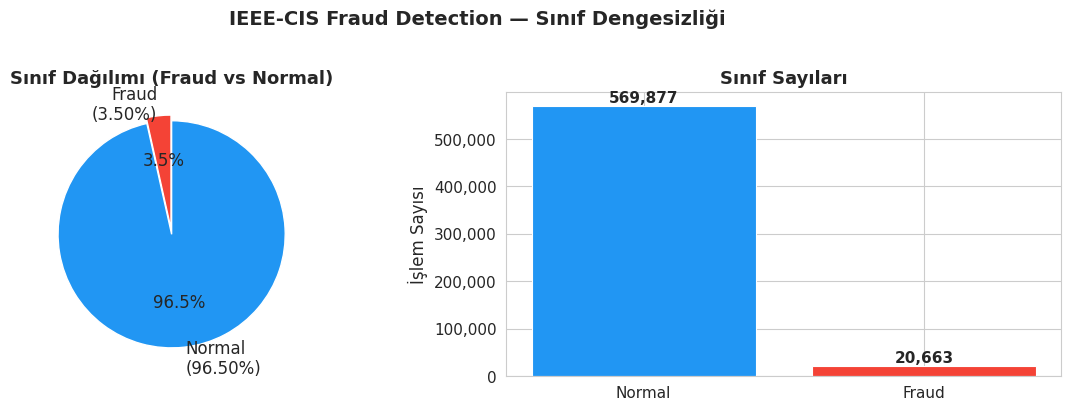

Kaydedildi: eda_01_fraud_distribution.png


In [ ]:
fraud_count  = df['isFraud'].sum()
normal_count = len(df) - fraud_count
fraud_rate   = df['isFraud'].mean() * 100

print('=== GENEL BAKIS ===')
print(f'Toplam islem  : {len(df):,}')
print(f'Fraud         : {fraud_count:,}  ({fraud_rate:.2f}%)')
print(f'Normal        : {normal_count:,}  ({100-fraud_rate:.2f}%)')
print(f'Sinif orani   : 1:{normal_count//fraud_count} (fraud:normal)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pasta grafigi
ax = axes[0]
sizes = [fraud_count, normal_count]
labels = [f'Fraud\n({fraud_rate:.2f}%)', f'Normal\n({100-fraud_rate:.2f}%)']
colors_pie = ['#F44336', '#2196F3']
wedges, texts, autotexts = ax.pie(
    sizes, labels=labels, colors=colors_pie,
    autopct='%1.1f%%', startangle=90,
    explode=(0.05, 0),
    textprops={'fontsize': 12}
)
ax.set_title('Sınıf Dağılımı (Fraud vs Normal)', fontsize=13, fontweight='bold')

# Bar grafigi (mutlak sayi)
ax = axes[1]
bars = ax.bar(['Normal', 'Fraud'], [normal_count, fraud_count],
              color=['#2196F3', '#F44336'], edgecolor='white', linewidth=0.8)
for bar, cnt in zip(bars, [normal_count, fraud_count]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
            f'{cnt:,}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylabel('İşlem Sayısı', fontsize=12)
ax.set_title('Sınıf Sayıları', fontsize=13, fontweight='bold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.suptitle('IEEE-CIS Fraud Detection — Sınıf Dengesizliği', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(SAVE_BASE + 'eda_01_fraud_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('Kaydedildi: eda_01_fraud_distribution.png')

## 3. TransactionAmt Analizi — Fraud vs Normal

Dolandırıcılık işlemlerinin tutar dağılımı normal işlemlerden farklı mı?

TRANSACTION AMT İSTATİSTİKLERİ
                       Fraud       Normal
------------------------------------------
mean                  149.24       134.51
median                 75.00        68.50
std                   232.21       239.40
min                     0.29         0.25
max                  5191.00     31937.39


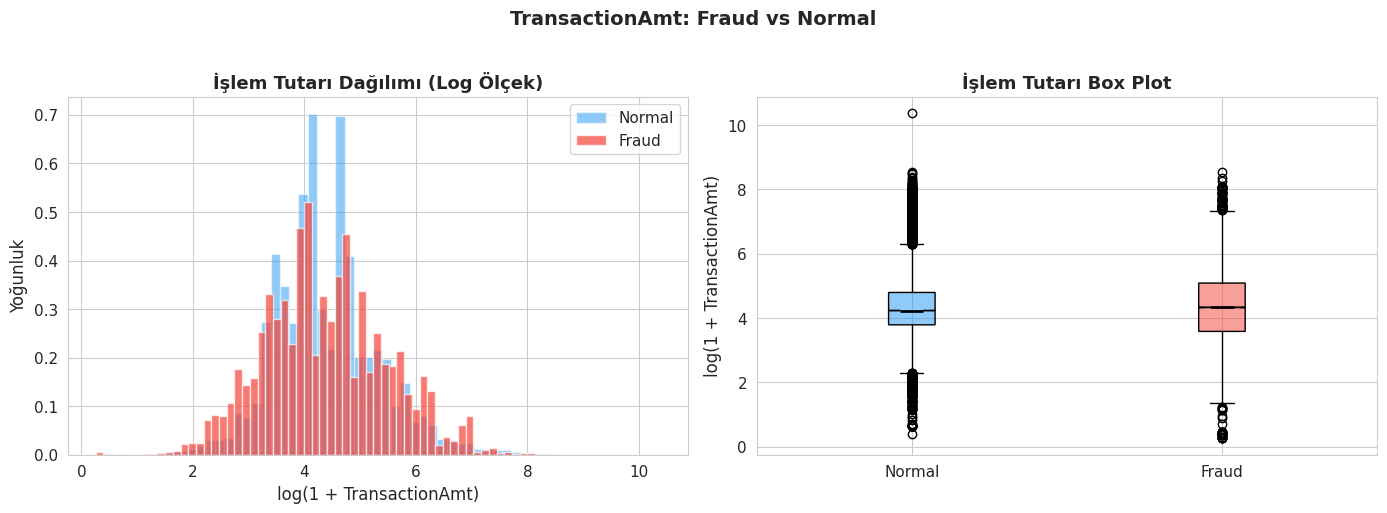

Kaydedildi: eda_02_transaction_amount.png


In [ ]:
fraud_amt  = df.loc[df['isFraud'] == 1, 'TransactionAmt']
normal_amt = df.loc[df['isFraud'] == 0, 'TransactionAmt']

print('TRANSACTION AMT İSTATİSTİKLERİ')
print(f'{"":<15} {"Fraud":>12} {"Normal":>12}')
print('-' * 42)
for stat in ['mean', 'median', 'std', 'min', 'max']:
    f_val = getattr(fraud_amt, stat)()
    n_val = getattr(normal_amt, stat)()
    print(f'{stat:<15} {f_val:>12.2f} {n_val:>12.2f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Log-scale KDE
ax = axes[0]
log_fraud  = np.log1p(fraud_amt)
log_normal = np.log1p(normal_amt.sample(min(50000, len(normal_amt)), random_state=42))
ax.hist(log_normal, bins=60, alpha=0.5, color='#2196F3', label='Normal', density=True)
ax.hist(log_fraud,  bins=60, alpha=0.7, color='#F44336', label='Fraud',  density=True)
ax.set_xlabel('log(1 + TransactionAmt)', fontsize=12)
ax.set_ylabel('Yoğunluk', fontsize=12)
ax.set_title('İşlem Tutarı Dağılımı (Log Ölçek)', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)

# Box plot (log scale)
ax = axes[1]
data_box = [
    np.log1p(normal_amt.sample(50000, random_state=42)),
    np.log1p(fraud_amt),
]
bp = ax.boxplot(data_box, labels=['Normal', 'Fraud'],
                patch_artist=True, notch=True,
                medianprops=dict(color='black', linewidth=2))
bp['boxes'][0].set_facecolor('#2196F380')
bp['boxes'][1].set_facecolor('#F4433680')
ax.set_ylabel('log(1 + TransactionAmt)', fontsize=12)
ax.set_title('İşlem Tutarı Box Plot', fontsize=13, fontweight='bold')

plt.suptitle('TransactionAmt: Fraud vs Normal', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(SAVE_BASE + 'eda_02_transaction_amount.png', dpi=150, bbox_inches='tight')
plt.show()
print('Kaydedildi: eda_02_transaction_amount.png')

## 4. Zaman Desenleri — Saatlik ve Günlük Fraud Oranları

`TransactionDT`: veri setinin başlangıcından bu yana saniye cinsinden.

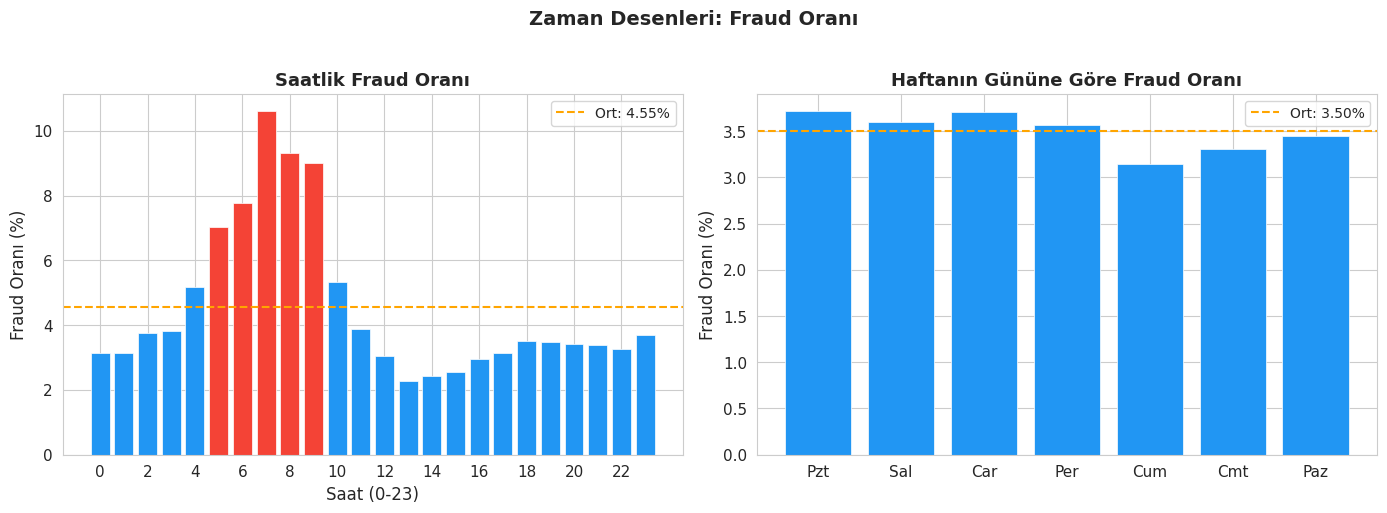

Kaydedildi: eda_03_time_patterns.png

En yuksek fraud oranli 5 saat:
         fraud_sayisi  toplam  fraud_orani_%
tx_hour                                     
7                 393    3704      10.610151
8                 241    2591       9.301428
9                 223    2479       8.995563
6                 467    6007       7.774263
5                 682    9701       7.030203


In [ ]:
df['tx_hour']     = (df['TransactionDT'] % 86400) // 3600
df['tx_day']      = df['TransactionDT'] // 86400
df['day_of_week'] = (df['TransactionDT'] // 86400) % 7

# Saatlik fraud orani
hourly = df.groupby('tx_hour')['isFraud'].agg(['sum', 'count'])
hourly['fraud_rate'] = hourly['sum'] / hourly['count'] * 100

# Gunluk fraud orani (7 gunluk periyot)
weekly = df.groupby('day_of_week')['isFraud'].agg(['sum', 'count'])
weekly['fraud_rate'] = weekly['sum'] / weekly['count'] * 100
day_names = ['Pzt', 'Sal', 'Car', 'Per', 'Cum', 'Cmt', 'Paz']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Saatlik
ax = axes[0]
bars = ax.bar(hourly.index, hourly['fraud_rate'],
              color=['#F44336' if r > hourly['fraud_rate'].mean() * 1.2 else '#2196F3'
                     for r in hourly['fraud_rate']],
              edgecolor='white', linewidth=0.5)
ax.axhline(y=hourly['fraud_rate'].mean(), color='orange', linestyle='--',
           linewidth=1.5, label=f'Ort: {hourly["fraud_rate"].mean():.2f}%')
ax.set_xlabel('Saat (0-23)', fontsize=12)
ax.set_ylabel('Fraud Oranı (%)', fontsize=12)
ax.set_title('Saatlik Fraud Oranı', fontsize=13, fontweight='bold')
ax.set_xticks(range(0, 24, 2))
ax.legend(fontsize=10)

# Haftalik
ax = axes[1]
colors_w = ['#F44336' if r > weekly['fraud_rate'].mean() * 1.1 else '#2196F3'
            for r in weekly['fraud_rate']]
ax.bar(range(7), weekly['fraud_rate'], color=colors_w, edgecolor='white', linewidth=0.5)
ax.axhline(y=weekly['fraud_rate'].mean(), color='orange', linestyle='--',
           linewidth=1.5, label=f'Ort: {weekly["fraud_rate"].mean():.2f}%')
ax.set_xticks(range(7))
ax.set_xticklabels(day_names, fontsize=11)
ax.set_ylabel('Fraud Oranı (%)', fontsize=12)
ax.set_title('Haftanın Gününe Göre Fraud Oranı', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)

plt.suptitle('Zaman Desenleri: Fraud Oranı', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(SAVE_BASE + 'eda_03_time_patterns.png', dpi=150, bbox_inches='tight')
plt.show()
print('Kaydedildi: eda_03_time_patterns.png')

# En yuksek fraud oranli saatler
print('\nEn yuksek fraud oranli 5 saat:')
print(hourly.sort_values('fraud_rate', ascending=False).head()[
    ['sum', 'count', 'fraud_rate']
].rename(columns={'sum': 'fraud_sayisi', 'count': 'toplam', 'fraud_rate': 'fraud_orani_%'}).to_string())

## 5. Zaman Serisi — Günlük Fraud Hacmi

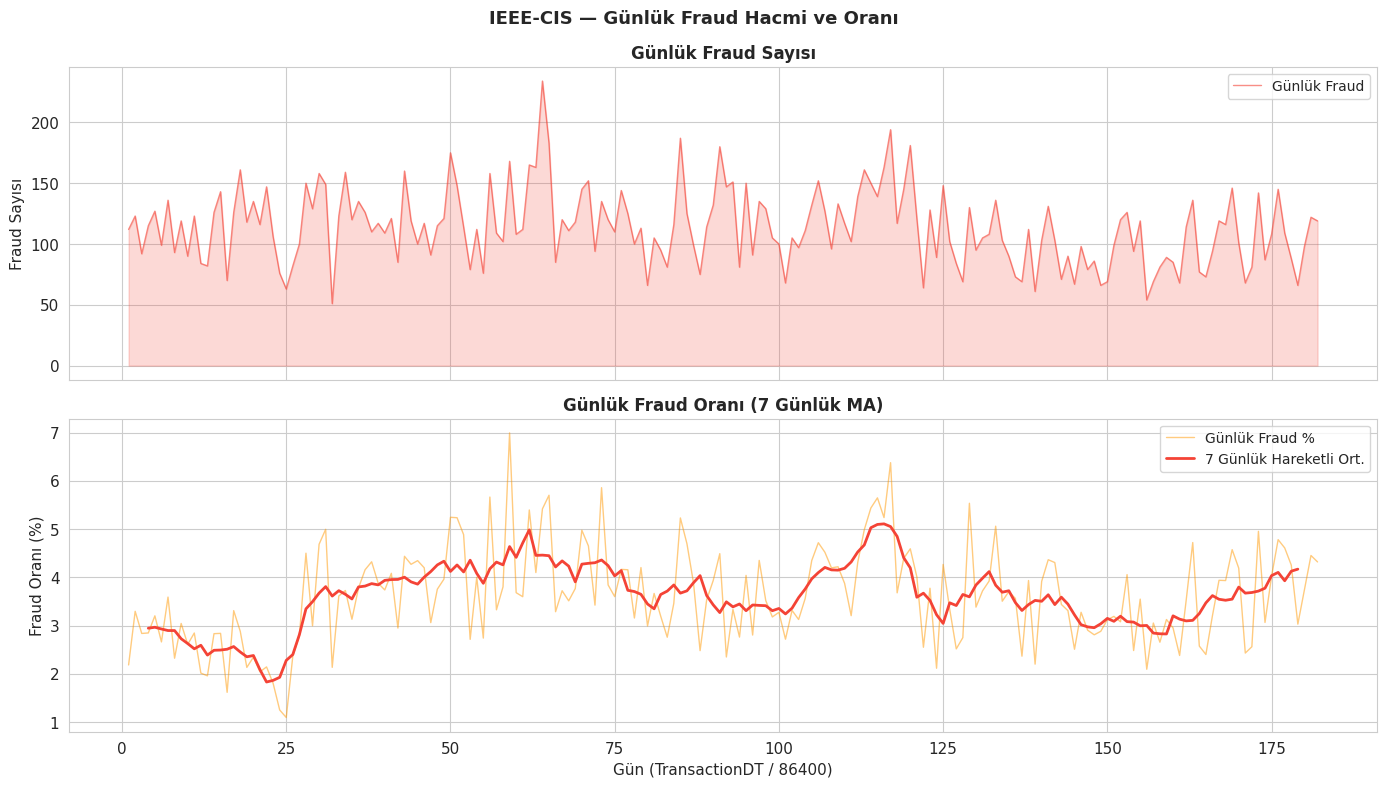

Kaydedildi: eda_04_daily_fraud_timeseries.png


In [ ]:
daily = df.groupby('tx_day')['isFraud'].agg(['sum', 'count'])
daily['fraud_rate'] = daily['sum'] / daily['count'] * 100
daily['fraud_ma7']  = daily['fraud_rate'].rolling(7, center=True).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

ax = axes[0]
ax.plot(daily.index, daily['sum'], color='#F44336', alpha=0.6, linewidth=1, label='Günlük Fraud')
ax.fill_between(daily.index, daily['sum'], alpha=0.2, color='#F44336')
ax.set_ylabel('Fraud Sayısı', fontsize=11)
ax.set_title('Günlük Fraud Sayısı', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)

ax = axes[1]
ax.plot(daily.index, daily['fraud_rate'], color='#FF9800', alpha=0.5, linewidth=1, label='Günlük Fraud %')
ax.plot(daily.index, daily['fraud_ma7'], color='#F44336', linewidth=2, label='7 Günlük Hareketli Ort.')
ax.set_xlabel('Gün (TransactionDT / 86400)', fontsize=11)
ax.set_ylabel('Fraud Oranı (%)', fontsize=11)
ax.set_title('Günlük Fraud Oranı (7 Günlük MA)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)

plt.suptitle('IEEE-CIS — Günlük Fraud Hacmi ve Oranı', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(SAVE_BASE + 'eda_04_daily_fraud_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()
print('Kaydedildi: eda_04_daily_fraud_timeseries.png')

## 6. Eksik Değer Analizi

Özellik gruplara göre eksik değer oranları — pipeline'daki %80 eşiği görselleştirilir.

Toplam eksik sutun sayisi: 414
>80% eksik sutun         : 74 (pipeline tarafindan atiliyor)

Grup bazli eksik deger ozeti:
                 sutun_sayisi  ort_eksik  max_eksik
grup                                               
id_ (kimlik)               38  84.823271  99.196159
dist                        2  76.640363  93.628374
D (zaman delta)            17  60.490010  93.409930
M (esleme)                  9  49.923328  59.349409
V (340 sutun)             339  43.038469  86.123717
Diger                       9  13.114588  76.751617


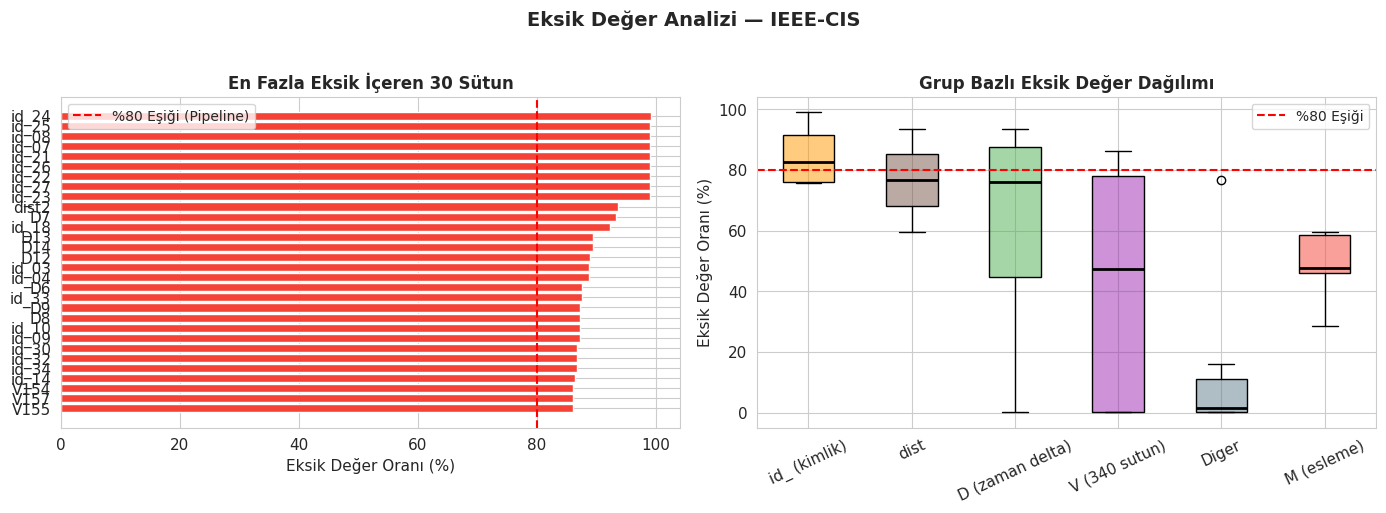

Kaydedildi: eda_05_missing_values.png


In [ ]:
missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

# Grup etiketleri
def col_group(col):
    if col.startswith('V'):    return 'V (340 sutun)'
    if col.startswith('id_'):  return 'id_ (kimlik)'
    if col.startswith('D'):    return 'D (zaman delta)'
    if col.startswith('C'):    return 'C (sayac)'
    if col.startswith('M'):    return 'M (esleme)'
    if col.startswith('dist'): return 'dist'
    return 'Diger'

missing_df = pd.DataFrame({
    'sutun'  : missing_pct.index,
    'eksik_pct': missing_pct.values,
    'grup'   : [col_group(c) for c in missing_pct.index],
})

print(f'Toplam eksik sutun sayisi: {len(missing_df)}')
print(f'>80% eksik sutun         : {(missing_df.eksik_pct > 80).sum()} (pipeline tarafindan atiliyor)')
print()

# Grup bazli ozet
grp_summary = missing_df.groupby('grup').agg(
    sutun_sayisi=('sutun', 'count'),
    ort_eksik=('eksik_pct', 'mean'),
    max_eksik=('eksik_pct', 'max'),
).sort_values('ort_eksik', ascending=False)
print('Grup bazli eksik deger ozeti:')
print(grp_summary.to_string())

# Grafik: eksik oran dagilimi
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sol: top 30 sutun
ax = axes[0]
top30 = missing_df.head(30)
colors_m = ['#F44336' if p > 80 else '#FF9800' if p > 50 else '#2196F3'
            for p in top30['eksik_pct']]
ax.barh(top30['sutun'][::-1], top30['eksik_pct'][::-1], color=colors_m[::-1])
ax.axvline(x=80, color='red', linestyle='--', linewidth=1.5,
           label='%80 Eşiği (Pipeline)')
ax.set_xlabel('Eksik Değer Oranı (%)', fontsize=11)
ax.set_title('En Fazla Eksik İçeren 30 Sütun', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)

# Sag: grup bazli kutu
ax = axes[1]
group_palette = {
    'V (340 sutun)': '#9C27B0', 'id_ (kimlik)': '#FF9800',
    'D (zaman delta)': '#4CAF50', 'C (sayac)': '#2196F3',
    'M (esleme)': '#F44336', 'dist': '#795548', 'Diger': '#607D8B'
}
groups = missing_df['grup'].unique()
data_grp = [missing_df.loc[missing_df['grup'] == g, 'eksik_pct'].values for g in groups]
bp = ax.boxplot(data_grp, labels=groups, patch_artist=True, notch=False,
                medianprops=dict(color='black', linewidth=2))
for patch, g in zip(bp['boxes'], groups):
    patch.set_facecolor(group_palette.get(g, '#9E9E9E') + '80')
ax.axhline(y=80, color='red', linestyle='--', linewidth=1.5, label='%80 Eşiği')
ax.set_ylabel('Eksik Değer Oranı (%)', fontsize=11)
ax.set_title('Grup Bazlı Eksik Değer Dağılımı', fontsize=12, fontweight='bold')
ax.tick_params(axis='x', rotation=25)
ax.legend(fontsize=10)

plt.suptitle('Eksik Değer Analizi — IEEE-CIS', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(SAVE_BASE + 'eda_05_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()
print('Kaydedildi: eda_05_missing_values.png')

## 7. Sayısal Özellik Korelasyonları (isFraud ile)

En yüksek Spearman korelasyonu olan sayısal özellikler.

Spearman korelasyonu hesaplaniyor (bu ~1-2 dk surebilir)...


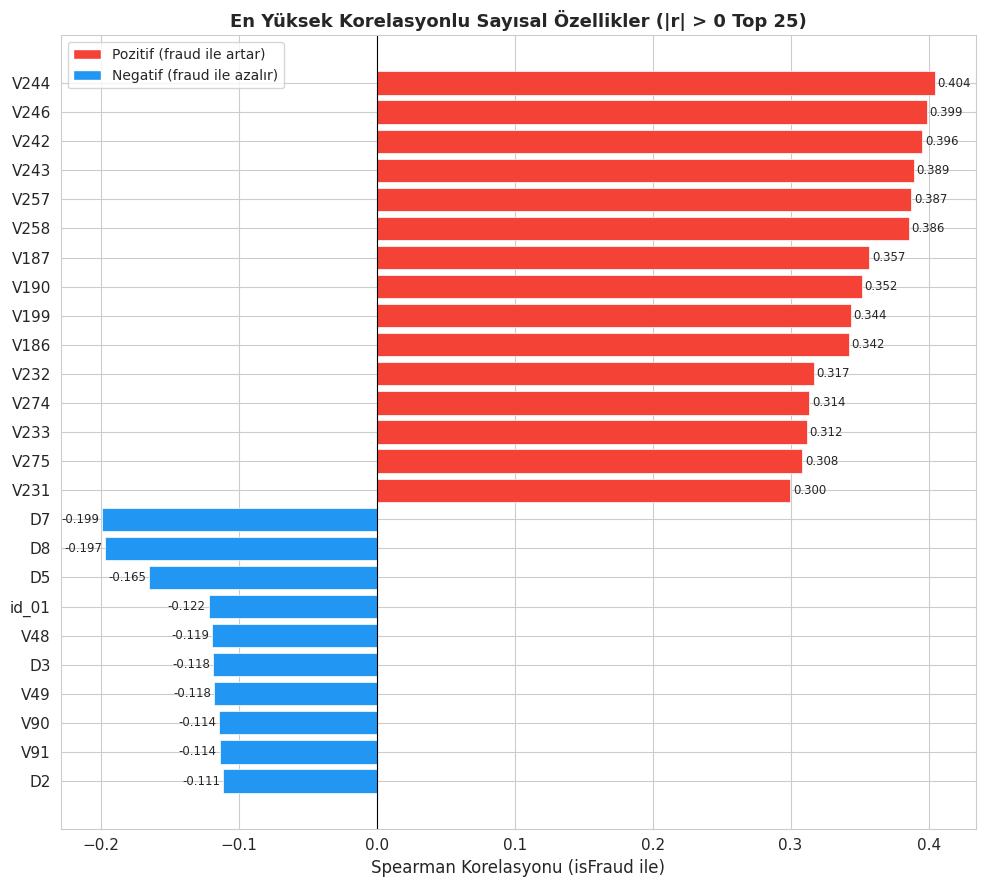

Kaydedildi: eda_06_numeric_correlations.png

Top 10 pozitif korelasyon:
V244    0.404460
V246    0.398693
V242    0.395531
V243    0.389075
V257    0.387434
V258    0.385553
V187    0.356946
V190    0.351649
V199    0.343503
V186    0.342284


In [ ]:
# Sadece sayisal sutunlar (object ve TransactionID haric)
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
num_cols = [c for c in num_cols if c not in ['isFraud', 'TransactionID', 'TransactionDT']]

# Spearman korelasyonu (fraud ile)
print('Spearman korelasyonu hesaplaniyor (bu ~1-2 dk surebilir)...')
corr_dict = {}
for col in num_cols:
    valid_mask = df[col].notna()
    if valid_mask.sum() < 1000:
        continue
    try:
        corr_val = df.loc[valid_mask, col].corr(df.loc[valid_mask, 'isFraud'], method='spearman')
        if not np.isnan(corr_val):
            corr_dict[col] = corr_val
    except Exception:
        pass

corr_series = pd.Series(corr_dict).sort_values(key=abs, ascending=False)
top_pos = corr_series[corr_series > 0].head(15)
top_neg = corr_series[corr_series < 0].head(15).sort_values()
top_combined = pd.concat([top_pos, top_neg]).sort_values(key=abs, ascending=False).head(25)

fig, ax = plt.subplots(figsize=(10, 9))
colors_corr = ['#F44336' if v > 0 else '#2196F3' for v in top_combined.values]
bars = ax.barh(
    top_combined.index[::-1],
    top_combined.values[::-1],
    color=colors_corr[::-1],
    edgecolor='white', linewidth=0.5
)
for bar, val in zip(bars, top_combined.values[::-1]):
    offset = 0.002 if val >= 0 else -0.002
    ha = 'left' if val >= 0 else 'right'
    ax.text(val + offset, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', ha=ha, fontsize=8.5)
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('Spearman Korelasyonu (isFraud ile)', fontsize=12)
ax.set_title(
    'En Yüksek Korelasyonlu Sayısal Özellikler (|r| > 0 Top 25)',
    fontsize=13, fontweight='bold'
)

# Kirmizi = pozitif korelasyon (fraud arttikca artiyor)
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#F44336', label='Pozitif (fraud ile artar)'),
    Patch(facecolor='#2196F3', label='Negatif (fraud ile azalır)'),
]
ax.legend(handles=legend_elements, fontsize=10)
plt.tight_layout()
plt.savefig(SAVE_BASE + 'eda_06_numeric_correlations.png', dpi=150, bbox_inches='tight')
plt.show()
print('Kaydedildi: eda_06_numeric_correlations.png')
print()
print('Top 10 pozitif korelasyon:')
print(top_pos.head(10).to_string())

## 8. Kategorik Değişken Dağılımları

ProductCD, card4 (kart marka), P_emaildomain — fraud oranı hangi kategorilerde yüksek?

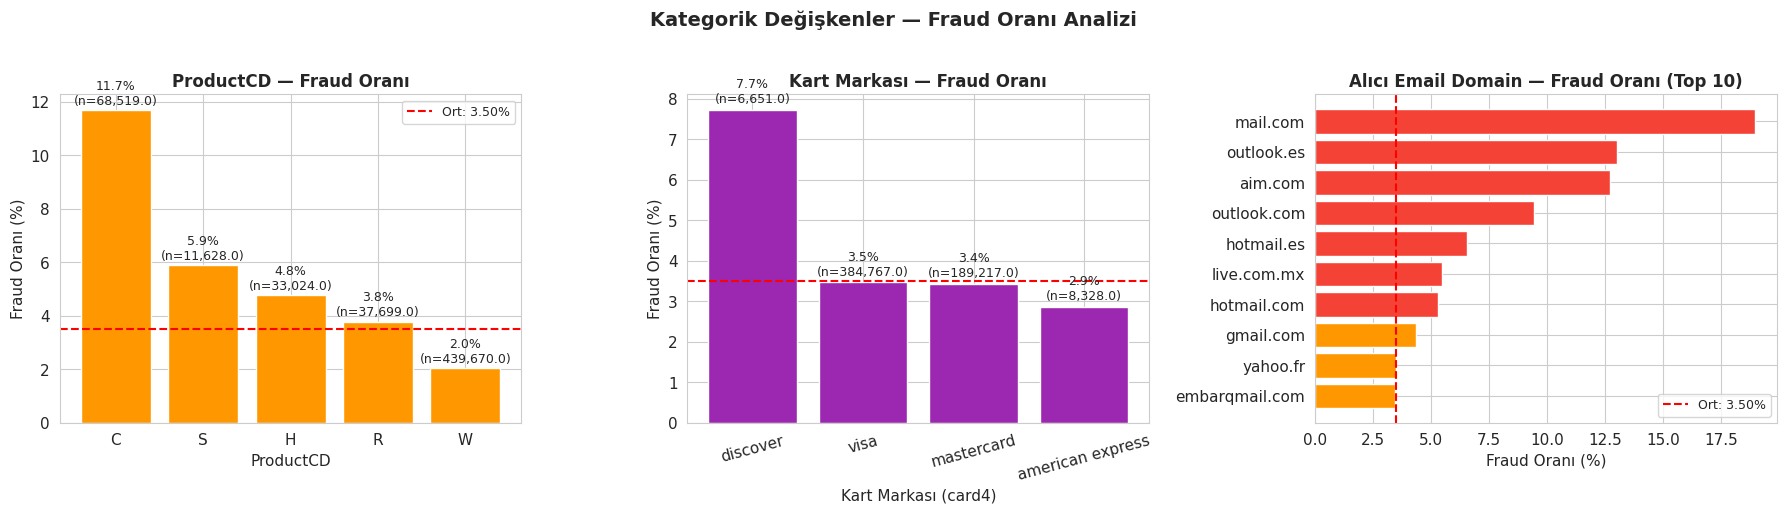

Kaydedildi: eda_07_categorical_fraud_rates.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ── ProductCD ────────────────────────────────────────────────────────────────
ax = axes[0]
prod_stats = df.groupby('ProductCD')['isFraud'].agg(['sum', 'count'])
prod_stats['fraud_rate'] = prod_stats['sum'] / prod_stats['count'] * 100
prod_stats = prod_stats.sort_values('fraud_rate', ascending=False)

bars = ax.bar(prod_stats.index, prod_stats['fraud_rate'],
              color='#FF9800', edgecolor='white')
for bar, (idx, row) in zip(bars, prod_stats.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
            f'{row["fraud_rate"]:.1f}%\n(n={row["count"]:,})',
            ha='center', va='bottom', fontsize=9)
ax.axhline(y=df['isFraud'].mean()*100, color='red', linestyle='--',
           linewidth=1.5, label=f'Ort: {df["isFraud"].mean()*100:.2f}%')
ax.set_xlabel('ProductCD', fontsize=11)
ax.set_ylabel('Fraud Oranı (%)', fontsize=11)
ax.set_title('ProductCD — Fraud Oranı', fontsize=12, fontweight='bold')
ax.legend(fontsize=9)

# ── Card4 (kart markasi) ─────────────────────────────────────────────────────
ax = axes[1]
card4_stats = df.groupby('card4')['isFraud'].agg(['sum', 'count'])
card4_stats['fraud_rate'] = card4_stats['sum'] / card4_stats['count'] * 100
card4_stats = card4_stats.sort_values('fraud_rate', ascending=False)

bars = ax.bar(card4_stats.index, card4_stats['fraud_rate'],
              color='#9C27B0', edgecolor='white')
for bar, (idx, row) in zip(bars, card4_stats.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
            f'{row["fraud_rate"]:.1f}%\n(n={row["count"]:,})',
            ha='center', va='bottom', fontsize=9)
ax.axhline(y=df['isFraud'].mean()*100, color='red', linestyle='--', linewidth=1.5)
ax.set_xlabel('Kart Markası (card4)', fontsize=11)
ax.set_ylabel('Fraud Oranı (%)', fontsize=11)
ax.set_title('Kart Markası — Fraud Oranı', fontsize=12, fontweight='bold')
ax.tick_params(axis='x', rotation=15)

# ── P_emaildomain (top 10) ───────────────────────────────────────────────────
ax = axes[2]
email_stats = df.groupby('P_emaildomain')['isFraud'].agg(['sum', 'count'])
email_stats['fraud_rate'] = email_stats['sum'] / email_stats['count'] * 100
# En az 100 islem olan domainler
email_stats = email_stats[email_stats['count'] >= 100].sort_values('fraud_rate', ascending=False).head(10)

colors_e = ['#F44336' if r > df['isFraud'].mean()*100*1.5 else '#FF9800'
            for r in email_stats['fraud_rate']]
ax.barh(email_stats.index[::-1], email_stats['fraud_rate'][::-1], color=colors_e[::-1])
ax.axvline(x=df['isFraud'].mean()*100, color='red', linestyle='--',
           linewidth=1.5, label=f'Ort: {df["isFraud"].mean()*100:.2f}%')
ax.set_xlabel('Fraud Oranı (%)', fontsize=11)
ax.set_title('Alıcı Email Domain — Fraud Oranı (Top 10)', fontsize=12, fontweight='bold')
ax.legend(fontsize=9)

plt.suptitle('Kategorik Değişkenler — Fraud Oranı Analizi', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(SAVE_BASE + 'eda_07_categorical_fraud_rates.png', dpi=150, bbox_inches='tight')
plt.show()
print('Kaydedildi: eda_07_categorical_fraud_rates.png')

## 9. Kart Tipi (card6) ve card1 Analizi

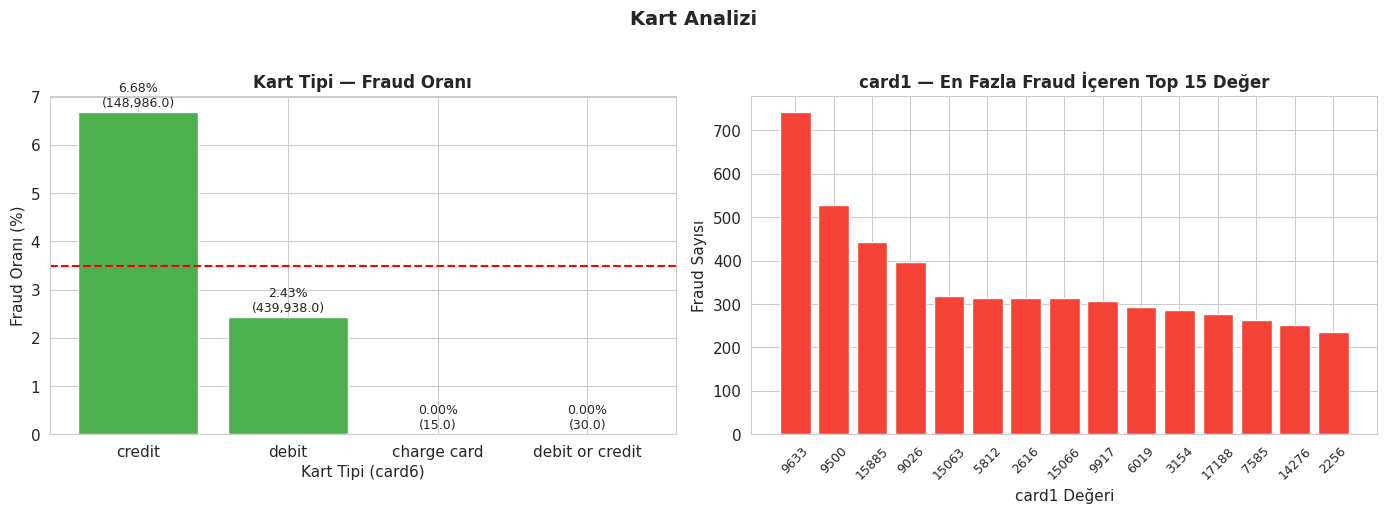

Kaydedildi: eda_08_card_analysis.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── card6 (debit/credit) ─────────────────────────────────────────────────────
ax = axes[0]
c6 = df.groupby('card6')['isFraud'].agg(['sum', 'count'])
c6['fraud_rate'] = c6['sum'] / c6['count'] * 100
c6 = c6.sort_values('fraud_rate', ascending=False)

bars = ax.bar(c6.index, c6['fraud_rate'], color='#4CAF50', edgecolor='white')
for bar, (idx, row) in zip(bars, c6.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{row["fraud_rate"]:.2f}%\n({row["count"]:,})',
            ha='center', va='bottom', fontsize=9)
ax.axhline(y=df['isFraud'].mean()*100, color='red', linestyle='--', linewidth=1.5)
ax.set_xlabel('Kart Tipi (card6)', fontsize=11)
ax.set_ylabel('Fraud Oranı (%)', fontsize=11)
ax.set_title('Kart Tipi — Fraud Oranı', fontsize=12, fontweight='bold')

# ── card1 en cok fraud gorülen degerler ──────────────────────────────────────
ax = axes[1]
c1 = df.groupby('card1')['isFraud'].agg(['sum', 'count'])
c1['fraud_rate'] = c1['sum'] / c1['count'] * 100
# En az 100 islem olanlardan en yuksek fraud oranlilar
c1_top = c1[c1['count'] >= 100].sort_values('sum', ascending=False).head(15)

ax.bar(range(len(c1_top)), c1_top['sum'], color='#F44336', edgecolor='white')
ax.set_xticks(range(len(c1_top)))
ax.set_xticklabels(c1_top.index, rotation=45, fontsize=9)
ax.set_xlabel('card1 Değeri', fontsize=11)
ax.set_ylabel('Fraud Sayısı', fontsize=11)
ax.set_title('card1 — En Fazla Fraud İçeren Top 15 Değer', fontsize=12, fontweight='bold')

plt.suptitle('Kart Analizi', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(SAVE_BASE + 'eda_08_card_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('Kaydedildi: eda_08_card_analysis.png')

## 10. Kimlik Tablosu (train_identity) Analizi

Kimlik tablosu tüm işlemlerin yalnızca ~%46'sı için mevcut.  
Kimlik bilgisi olan vs olmayan işlemlerde fraud oranı farkı nedir?

KİMLİK TABLOSU ANALİZİ:
            fraud_sayisi  toplam  fraud_orani_%
Kimlik Yok          9345  446307       2.093850
Kimlik Var         11318  144233       7.847025


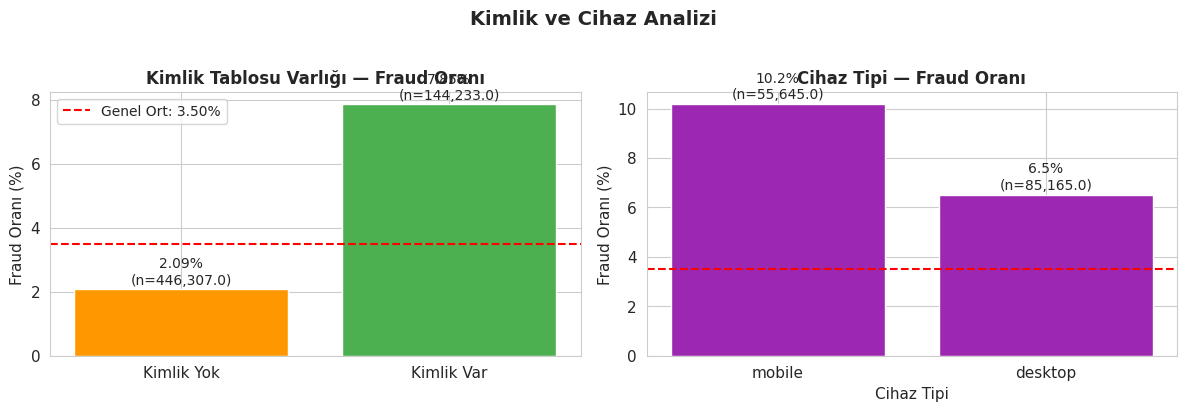

Kaydedildi: eda_09_identity_device.png


In [ ]:
df['has_identity'] = df['id_01'].notna().astype(int)  # id_01 kimlik tablosundan

id_stats = df.groupby('has_identity')['isFraud'].agg(['sum', 'count'])
id_stats['fraud_rate'] = id_stats['sum'] / id_stats['count'] * 100
id_stats.index = ['Kimlik Yok', 'Kimlik Var']

print('KİMLİK TABLOSU ANALİZİ:')
print(id_stats.rename(columns={'sum': 'fraud_sayisi', 'count': 'toplam', 'fraud_rate': 'fraud_orani_%'}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
bars = ax.bar(id_stats.index, id_stats['fraud_rate'],
              color=['#FF9800', '#4CAF50'], edgecolor='white')
for bar, (idx, row) in zip(bars, id_stats.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{row["fraud_rate"]:.2f}%\n(n={row["count"]:,})',
            ha='center', va='bottom', fontsize=10)
ax.axhline(y=df['isFraud'].mean()*100, color='red', linestyle='--',
           linewidth=1.5, label=f'Genel Ort: {df["isFraud"].mean()*100:.2f}%')
ax.set_ylabel('Fraud Oranı (%)', fontsize=11)
ax.set_title('Kimlik Tablosu Varlığı — Fraud Oranı', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)

# DeviceType analizi (eger varsa)
ax = axes[1]
if 'DeviceType' in df.columns:
    dt = df.groupby('DeviceType')['isFraud'].agg(['sum', 'count'])
    dt['fraud_rate'] = dt['sum'] / dt['count'] * 100
    dt = dt.dropna().sort_values('fraud_rate', ascending=False)
    bars2 = ax.bar(dt.index, dt['fraud_rate'], color='#9C27B0', edgecolor='white')
    for bar, (idx, row) in zip(bars2, dt.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                f'{row["fraud_rate"]:.1f}%\n(n={row["count"]:,})',
                ha='center', va='bottom', fontsize=10)
    ax.axhline(y=df['isFraud'].mean()*100, color='red', linestyle='--', linewidth=1.5)
    ax.set_xlabel('Cihaz Tipi', fontsize=11)
    ax.set_ylabel('Fraud Oranı (%)', fontsize=11)
    ax.set_title('Cihaz Tipi — Fraud Oranı', fontsize=12, fontweight='bold')
else:
    ax.text(0.5, 0.5, 'DeviceType\nbu veri setinde bulunamadi',
            ha='center', va='center', transform=ax.transAxes, fontsize=12)
    ax.set_title('Cihaz Tipi', fontsize=12)

plt.suptitle('Kimlik ve Cihaz Analizi', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(SAVE_BASE + 'eda_09_identity_device.png', dpi=150, bbox_inches='tight')
plt.show()
print('Kaydedildi: eda_09_identity_device.png')

## 11. Tutar — Fraud Yoğun Aralıklar ve Round Number Etkisi

YUVARLAK TUTAR ANALİZİ:
          fraud  toplam   fraud_%
Kuruşlu    9781  285527  3.425595
Yuvarlak  10882  305013  3.567717


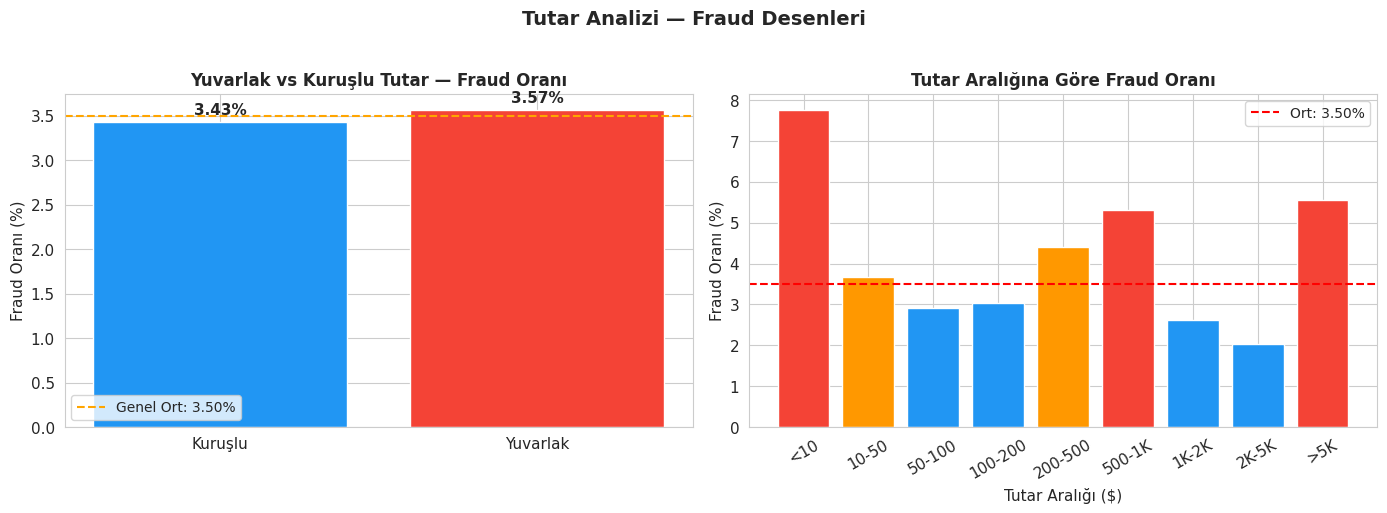

Kaydedildi: eda_10_amount_patterns.png


In [ ]:
# Yuvarlak tutar mi? (cent = 0)
df['is_round_amt'] = ((df['TransactionAmt'] % 1) == 0).astype(int)

round_stats = df.groupby('is_round_amt')['isFraud'].agg(['sum', 'count'])
round_stats['fraud_rate'] = round_stats['sum'] / round_stats['count'] * 100
round_stats.index = ['Kuruşlu', 'Yuvarlak']

print('YUVARLAK TUTAR ANALİZİ:')
print(round_stats.rename(columns={'sum': 'fraud', 'count': 'toplam', 'fraud_rate': 'fraud_%'}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Yuvarlak tutar bar
ax = axes[0]
bars = ax.bar(round_stats.index, round_stats['fraud_rate'],
              color=['#2196F3', '#F44336'], edgecolor='white')
for bar, (idx, row) in zip(bars, round_stats.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f'{row["fraud_rate"]:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.axhline(y=df['isFraud'].mean()*100, color='orange', linestyle='--',
           linewidth=1.5, label=f'Genel Ort: {df["isFraud"].mean()*100:.2f}%')
ax.set_ylabel('Fraud Oranı (%)', fontsize=11)
ax.set_title('Yuvarlak vs Kuruşlu Tutar — Fraud Oranı', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)

# Tutar araliklar
ax = axes[1]
bins = [0, 10, 50, 100, 200, 500, 1000, 2000, 5000, np.inf]
labels_b = ['<10', '10-50', '50-100', '100-200', '200-500',
            '500-1K', '1K-2K', '2K-5K', '>5K']
df['amt_bin'] = pd.cut(df['TransactionAmt'], bins=bins, labels=labels_b)
bin_stats = df.groupby('amt_bin', observed=False)['isFraud'].agg(['sum', 'count'])
bin_stats['fraud_rate'] = bin_stats['sum'] / bin_stats['count'] * 100

colors_b = ['#F44336' if r > df['isFraud'].mean()*100*1.3 else '#FF9800'
            if r > df['isFraud'].mean()*100 else '#2196F3'
            for r in bin_stats['fraud_rate']]
ax.bar(bin_stats.index, bin_stats['fraud_rate'], color=colors_b, edgecolor='white')
ax.axhline(y=df['isFraud'].mean()*100, color='red', linestyle='--',
           linewidth=1.5, label=f'Ort: {df["isFraud"].mean()*100:.2f}%')
ax.set_xlabel('Tutar Aralığı ($)', fontsize=11)
ax.set_ylabel('Fraud Oranı (%)', fontsize=11)
ax.set_title('Tutar Aralığına Göre Fraud Oranı', fontsize=12, fontweight='bold')
ax.tick_params(axis='x', rotation=30)
ax.legend(fontsize=10)

plt.suptitle('Tutar Analizi — Fraud Desenleri', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(SAVE_BASE + 'eda_10_amount_patterns.png', dpi=150, bbox_inches='tight')
plt.show()
print('Kaydedildi: eda_10_amount_patterns.png')

## 12. EDA Özeti ve Bulgular

In [ ]:
print('=' * 65)
print('  EDA ÖZET — IEEE-CIS Fraud Detection')
print('=' * 65)
print()
print('VERI SETİ')
print(f'  Toplam islem  : {len(df):,}')
print(f'  Fraud orani   : {df["isFraud"].mean()*100:.2f}% (ciddi sinif dengesizligi)')
print(f'  Sutun sayisi  : {df.shape[1]}')
print(f'  Kimlik olan   : {df["has_identity"].mean()*100:.1f}% isleme kimlik bilgisi eslesebiliyor')
print()
print('TEMEL BULGULAR')
print('  1. Sinif Dengesizligi: ~1:28 fraud/normal oran')
print('     → class_weight="balanced" veya scale_pos_weight zorunlu')
print()
print('  2. Tutar Farki:')
print(f'     Fraud medyan: ${fraud_amt.median():.2f} | Normal medyan: ${normal_amt.median():.2f}')
print('     Yuksek tutarli islemlerde fraud orani daha fazla')
print()
print('  3. Zaman Deseni:')
gece_rate = df[df['tx_hour'].between(0, 8)]['isFraud'].mean()*100
gunduz_rate = df[df['tx_hour'].between(9, 17)]['isFraud'].mean()*100
print(f'     Gece (00-08) fraud orani: {gece_rate:.2f}%')
print(f'     Gunduz (09-17) fraud orani: {gunduz_rate:.2f}%')
print()
print('  4. Kategorik Bulgular:')
print(f'     ProductCD: C ve H en yuksek fraud oranli urunler')
print(f'     Kart markasi: discover en yuksek fraud oranli')
print()
print('  5. Eksik Deger:')
print(f'     V sutunlari (340 adet) cok fazla eksik iceriyor')
print(f'     Pipeline %80 esigi ile {(missing_df.eksik_pct > 80).sum()} sutunu atiyor')
print()
print('KAYDEDILEN DOSYALAR:')
eda_files = [
    'eda_01_fraud_distribution.png',
    'eda_02_transaction_amount.png',
    'eda_03_time_patterns.png',
    'eda_04_daily_fraud_timeseries.png',
    'eda_05_missing_values.png',
    'eda_06_numeric_correlations.png',
    'eda_07_categorical_fraud_rates.png',
    'eda_08_card_analysis.png',
    'eda_09_identity_device.png',
    'eda_10_amount_patterns.png',
]
for f in eda_files:
    print(f'    {SAVE_BASE}{f}')
print('=' * 65)

  EDA ÖZET — IEEE-CIS Fraud Detection

VERI SETİ
  Toplam islem  : 590,540
  Fraud orani   : 3.50% (ciddi sinif dengesizligi)
  Sutun sayisi  : 440
  Kimlik olan   : 24.4% isleme kimlik bilgisi eslesebiliyor

TEMEL BULGULAR
  1. Sinif Dengesizligi: ~1:28 fraud/normal oran
     → class_weight="balanced" veya scale_pos_weight zorunlu

  2. Tutar Farki:
     Fraud medyan: $75.00 | Normal medyan: $68.50
     Yuksek tutarli islemlerde fraud orani daha fazla

  3. Zaman Deseni:
     Gece (00-08) fraud orani: 4.24%
     Gunduz (09-17) fraud orani: 2.93%

  4. Kategorik Bulgular:
     ProductCD: C ve H en yuksek fraud oranli urunler
     Kart markasi: discover en yuksek fraud oranli

  5. Eksik Deger:
     V sutunlari (340 adet) cok fazla eksik iceriyor
     Pipeline %80 esigi ile 74 sutunu atiyor

KAYDEDILEN DOSYALAR:
    /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/EDA/eda_01_fraud_distribution.png
    /content/drive/My Drive/Bitirme/15-Mayıs-Cuma/EDA/eda_02_transaction_amount.png
    /cont

In [1]:
print(len(v_cols))

NameError: name 'v_cols' is not defined